# Systemy inspekcji wizualnej
## Laboratorium 2
Temat: Wczytywanie, wyświetlanie i zapisywanie obrazów oraz sekwencji obrazów w bibliotece OpenCV.

Instrukcję opracował: dr inż. Łukasz Jeleń

Wrocław 2026

---

Nazwisko i Imię: Aleksander Łyskawa 

Nr albumu: 275462

Data wykonania ćwiczenia: 13.10.2026

w celu zachowania przeniesienia do kolejnej linii należy się upewnić, że na końcu linii znajdują się 2 spacje

***

# 0. Zasady realizacji ćwiczenia

Notatnik składa się z dwóch części o odmiennym charakterze:

| Część | Charakter | Sposób realizacji | Punkty |
|---|---|---|---|
| **Sekcja 2 — Tutorial** | kod kompletny i uruchamialny, po każdym punkcie krótkie ćwiczenie kontrolne | komórki należy uruchamiać kolejno, zapoznając się z komentarzem, a następnie wykonać ćwiczenie **Do wykonania** | nd. |
| **Sekcja 3 — Zadania** | kod należy napisać samodzielnie | należy rozwiązać zadania i wypełnić komórki *Obserwacje i wnioski* | 30 |

Ćwiczenia kontrolne w sekcji 2 są krótkie — każde sprowadza się do modyfikacji kodu przedstawionego bezpośrednio nad nim — lecz ich wykonanie jest warunkiem zaliczenia ćwiczenia.

**Zakres pracy.** Należy przesłać niniejszy notatnik z uzupełnioną **sekcją 2 i sekcją 3**, **wykonanymi komórkami** (widoczne wyniki) oraz wypełnionymi komórkami *Obserwacje i wnioski*. Notatnik bez wypełnionych obserwacji nie podlega ocenie.

**Nazwa pliku:** `Lab2_Nazwisko_NrAlbumu.ipynb`. Notatnik należy przesłać przez e-portal.

***

# 1. Narzędzia

Na zajęciach będziemy korzystali z Pythona, który jest stosunkowo prostym językiem programowania. Mają Państwo do wyboru korzystanie z Google Colab (https://colab.research.google.com) - wersja online, lub Anaconda Navigator (https://www.anaconda.com/), ale ta  wymaga instalacji na własnym komputerze. Są to oczywiście tylko propozycje.

**Trzy uwagi pozwalające uniknąć najczęstszych błędów:**

1. `cv2.imshow()` **nie działa** ani w Jupyterze, ani w Colabie - zawiesza jądro. Wyświetlamy przez `matplotlib`.
2. `cv2.imread()` przy błędnej ścieżce **nie zgłasza błędu** - po cichu zwraca `None`, a program wywala się dopiero kilka linii dalej, w zupełnie innym miejscu. Dlatego poniżej jest funkcja `wczytaj()`, która to sprawdza.
3. OpenCV trzyma kanały w kolejności **BGR**, a `matplotlib` oczekuje **RGB**. Zagadnienie to omówiono w punkcie 2.1.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("OpenCV:", cv2.__version__)

DANE = Path("data")
WYNIKI = Path("wyniki")

DANE.mkdir(exist_ok=True)
WYNIKI.mkdir(exist_ok=True)


def wczytaj(nazwa, flaga=cv2.IMREAD_COLOR):
    """Wczytuje obraz i zglasza czytelny blad, gdy pliku nie ma."""
    sciezka = DANE / nazwa
    obraz = cv2.imread(str(sciezka), flaga)
    if obraz is None:
        raise FileNotFoundError(f"Nie udalo sie wczytac: {sciezka.resolve()}")
    return obraz


def pokaz(*obrazy, tytuly=None, cmap="gray", rozmiar=4):
    """Wyswietla jeden lub wiele obrazow obok siebie.

    Dla obrazow 1-kanalowych uzywa cmap i stalego zakresu 0-255,
    dla 3-kanalowych zaklada, ze podano je juz w RGB.
    """
    n = len(obrazy)
    fig, osie = plt.subplots(1, n, figsize=(rozmiar * n, rozmiar))
    if n == 1:
        osie = [osie]
    for i, (ax, img) in enumerate(zip(osie, obrazy)):
        if img.ndim == 2:
            ax.imshow(img, cmap=cmap, vmin=0, vmax=255)
        else:
            ax.imshow(img)
        ax.set_title(tytuly[i] if tytuly else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

OpenCV: 5.0.0


W Google Colab pliki wgrywamy przez panel po lewej stronie albo poleceniem:

```python
from google.colab import files
files.upload()
```

## 1.1 Dane do ćwiczenia

W komórce poniżej **generowany jest komplet obrazów testowych**, dzięki czemu notatnik działa bez konieczności pobierania dodatkowych plików. Komórkę należy uruchomić tylko raz.

W przypadku korzystania z obrazów udostępnionych na e-portalu należy podmienić nazwy plików w dalszych komórkach; logika pozostaje bez zmian.

In [2]:
def wzorzec_paskowy(h=238, w=225, tlo=10, pasek=190):
    """Pionowy wzorzec paskowy (bar target) o rosnacej szerokosci paskow."""
    img = np.full((h, w), tlo, np.uint8)
    x, szer = 0, 1
    while x < w:
        img[:, x:min(x + szer, w)] = pasek
        x += 2 * szer
        szer += 1
    return img


def scena_kolorowa(h=240, w=320):
    """Prosta scena z obiektami o czystych barwach - do cwiczen z kanalami."""
    img = np.full((h, w, 3), 230, np.uint8)          # jasne tlo (BGR)
    cv2.rectangle(img, (20, 40), (110, 150), (40, 40, 220), -1)    # czerwony
    cv2.circle(img, (175, 95), 55, (60, 180, 60), -1)              # zielony
    cv2.rectangle(img, (235, 40), (305, 150), (210, 90, 40), -1)   # niebieski
    cv2.putText(img, "SIW", (30, 215), cv2.FONT_HERSHEY_SIMPLEX, 2.0, (30, 30, 30), 4)
    return img


def tarcza_tnaca(h=240, w=240, uszkodzona=False, ziarno=0):
    """Tarcza tnaca do szlifierki katowej - egzemplarz wzorcowy i z wadami.

    """
    rng = np.random.default_rng(ziarno)
    srodek = (w // 2, h // 2)
    R, r_otw = 105, 24

    y, x = np.indices((h, w))
    faktura = (62.0
               + rng.normal(0, 6.0, (h, w))                     # ziarno sciernicy
               + 7.0 * ((x + y) % 7 < 2)                        # zbrojenie, splot 1
               + 7.0 * ((x - y) % 7 < 2))                       # zbrojenie, splot 2
    faktura = np.clip(faktura, 0, 255).astype(np.uint8)

    maska = np.zeros((h, w), np.uint8)
    cv2.circle(maska, srodek, R, 255, -1)            # korpus tarczy
    cv2.circle(maska, srodek, r_otw, 0, -1)          # otwor montazowy

    if uszkodzona:
        # wyszczerbienie krawedzi tnacej
        cv2.circle(maska, (srodek[0] + 93, srodek[1] - 46), 17, 0, -1)
        # peknięcie promieniowe od otworu
        cv2.line(maska, (srodek[0] - 30, srodek[1] + 26),
                        (srodek[0] - 72, srodek[1] + 64), 0, 3)

    img = np.full((h, w), 228, np.uint8)             # tlo stanowiska
    img[maska > 0] = faktura[maska > 0]
    return img


def nierowne_oswietlenie(h=240, w=320):
    """Jasny obiekt na tle z silnym gradientem oswietlenia."""
    gradient = np.tile(np.linspace(40, 215, w, dtype=np.float32), (h, 1))
    img = gradient.astype(np.uint8)
    cv2.putText(img, "INSPEKCJA", (15, 140), cv2.FONT_HERSHEY_SIMPLEX, 1.1, 20, 3)
    cv2.rectangle(img, (30, 170), (290, 200), 25, -1)
    return np.clip(img, 0, 255).astype(np.uint8)


def sekwencja_testowa(plik, n=120, h=240, w=320, fps=25):
    """Krotka sekwencja: jasny kwadrat przesuwajacy sie w poziomie."""
    zapis = cv2.VideoWriter(str(plik), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    for k in range(n):
        klatka = np.full((h, w, 3), 35, np.uint8)
        x = int(20 + (w - 80) * k / n)
        cv2.rectangle(klatka, (x, 90), (x + 50, 140), (80, 200, 230), -1)
        cv2.putText(klatka, f"{k:03d}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)
        zapis.write(klatka)
    zapis.release()


cv2.imwrite(str(DANE / "wzorzec_paskowy.png"), wzorzec_paskowy())
cv2.imwrite(str(DANE / "scena.png"), scena_kolorowa())
cv2.imwrite(str(DANE / "tarcza_wzorzec.png"), tarcza_tnaca(uszkodzona=False))
cv2.imwrite(str(DANE / "tarcza_badana.png"), tarcza_tnaca(uszkodzona=True))
cv2.imwrite(str(DANE / "nierowne.png"), nierowne_oswietlenie())
sekwencja_testowa(DANE / "sekwencja.mp4")

print("Wygenerowano pliki:")
for p in sorted(DANE.glob("*")):
    if p.suffix in {".png", ".mp4"}:
        print(" ", p.name, p.stat().st_size, "B")

Wygenerowano pliki:
  nierowne.png 14232 B
  scena.png 7643 B
  sekwencja.mp4 60258 B
  tarcza_badana.png 24372 B
  tarcza_wzorzec.png 24696 B
  wzorzec_paskowy.png 8195 B


***

# 2. Tutorial

Komórki należy uruchamiać kolejno, zapoznając się z komentarzem. Z przedstawionych tu rozwiązań należy korzystać przy realizacji zadań z sekcji 3.

Każdy punkt zakończony jest krótkim ćwiczeniem **Do wykonania**, stanowiącym modyfikację kodu przedstawionego wcześniej.

## 2.1 Wczytanie obrazu i pułapka BGR

`cv2.imread()` zwraca tablicę NumPy z kanałami w kolejności **B, G, R**. `plt.imshow()` interpretuje trzeci wymiar jako **R, G, B**. Jeżeli nie wykonamy konwersji, czerwony i niebieski zamienią się miejscami.

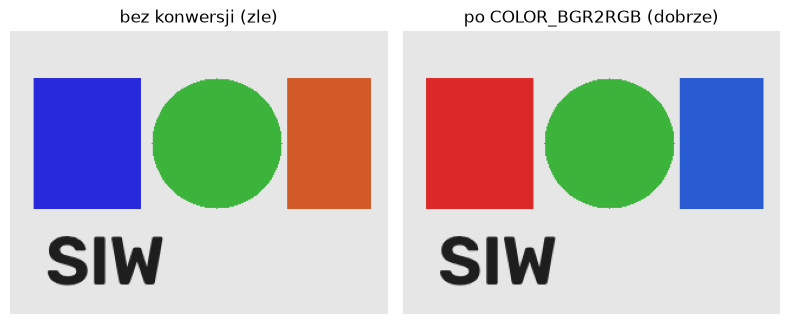

Piksel (95, 60) jako BGR: [ 40  40 220]
Piksel (95, 60) jako RGB: [220  40  40]


In [3]:
bgr = wczytaj("scena.png")
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

pokaz(bgr, rgb, tytuly=["bez konwersji (zle)", "po COLOR_BGR2RGB (dobrze)"])

print("Piksel (95, 60) jako BGR:", bgr[95, 60])
print("Piksel (95, 60) jako RGB:", rgb[95, 60])

Należy zwrócić uwagę, że **indeks ma postać `[wiersz, kolumna]`, czyli `[y, x]`**, czyli odwrotnie niż w zapisie współrzędnych punktu. Jest to źródło znacznej części pomyłek na początkowym etapie pracy.

Błąd BGR/RGB nie ujawni się na obrazie w odcieniach szarości ani na zdjęciu o stonowanych barwach. Z tego powodu bywa wykrywany dopiero na końcowym etapie pracy.

### Do wykonania 2.1

Konwersję BGR -> RGB można wykonać również zwykłym odwróceniem kolejności kanałów: `obraz[:, :, ::-1]`.

Należy wyznaczyć oba warianty i sprawdzić funkcją `np.array_equal`, czy dają taki sam wynik. Dodatkowo należy podać wartość piksela o współrzędnych `y = 95`, `x = 265` w obu zapisach i wskazać, który obiekt sceny się w nim znajduje.

In [4]:
bgr = wczytaj("scena.png")
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
rgb_reversed = bgr[:, :, ::-1]
is_equal = np.array_equal(rgb, rgb_reversed)
print("Are the images equal:", is_equal)

y, x = 95, 265

pixel_bgr = bgr[y, x]
pixel_rgb = rgb[y, x]

print(f"Pixel ({y}, {x}) as BGR:", pixel_bgr)
print(f"Pixel ({y}, {x}) as RGB:", pixel_rgb)

#Piksel (95, 265) tworzy niebeiski prostokat  

Are the images equal: True
Pixel (95, 265) as BGR: [210  90  40]
Pixel (95, 265) as RGB: [ 40  90 210]


## 2.2 Anatomia obrazu

Obraz jest zwykłą tablicą NumPy. Typ danych i zakres wartości należy ustalić na samym początku, ponieważ arytmetyka na typie `uint8` zachowuje się inaczej, niż wynikałoby to z intuicji.

In [5]:
szary = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)

print("ksztalt (h, w)      :", szary.shape)
print("typ danych          :", szary.dtype)
print("min / max           :", szary.min(), "/", szary.max())
print("liczba pikseli      :", szary.size)
print("unikalne poziomy    :", np.unique(szary))

# UWAGA: arytmetyka na uint8 ZAWIJA SIE, funkcje OpenCV NASYCAJA
a = np.array([[250]], np.uint8)
b = np.array([[ 10]], np.uint8)
c = np.array([[  5]], np.uint8)
d = np.array([[ 20]], np.uint8)

print("\n  250 + 10  operatorem '+' :", (a + b).ravel()[0], "  <- przepelnienie, zawinelo sie")
print("  250 + 10  cv2.add        :", cv2.add(a, b).ravel()[0], "  <- nasycenie do 255")
print("    5 - 20  operatorem '-' :", (c - d).ravel()[0], "  <- wartosc ujemna zawinela sie w gore")
print("    5 - 20  cv2.subtract   :", cv2.subtract(c, d).ravel()[0], "  <- obciecie do 0")
print("    5 - 20  cv2.absdiff    :", cv2.absdiff(c, d).ravel()[0], "  <- modul roznicy")

ksztalt (h, w)      : (238, 225)
typ danych          : uint8
min / max           : 10 / 190
liczba pikseli      : 53550
unikalne poziomy    : [ 10 190]

  250 + 10  operatorem '+' : 4   <- przepelnienie, zawinelo sie
  250 + 10  cv2.add        : 255   <- nasycenie do 255
    5 - 20  operatorem '-' : 241   <- wartosc ujemna zawinela sie w gore
    5 - 20  cv2.subtract   : 0   <- obciecie do 0
    5 - 20  cv2.absdiff    : 15   <- modul roznicy


W inspekcji wizualnej, ta rónica zamienia defekt w szum: przy odejmowaniu obrazów operator `-` na `uint8` zawija wartości ujemne do okolic 255, czyli **tworzy fałszywe jasne obszary tam, gdzie obraz badany jest ciemniejszy od wzorca**. Z tego powodu stosuje się `cv2.absdiff()` albo `cv2.subtract()`.

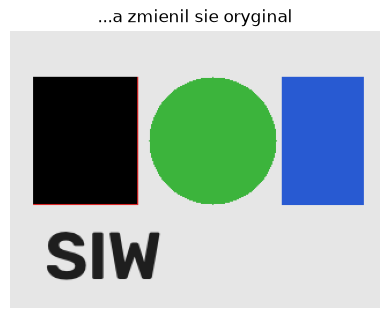

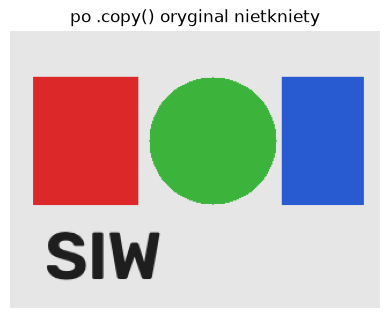

In [6]:
# ROI to WIDOK na oryginalna tablice, nie kopia
obraz = wczytaj("scena.png")
roi = obraz[40:150, 20:110]          # [y1:y2, x1:x2]
roi[:] = 0                            # modyfikujemy ROI...
pokaz(cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB), tytuly=["...a zmienil sie oryginal"])

# zeby tego uniknac:
obraz = wczytaj("scena.png")
roi_kopia = obraz[40:150, 20:110].copy()
roi_kopia[:] = 0
pokaz(cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB), tytuly=["po .copy() oryginal nietkniety"])

### Do wykonania 2.2

Należy rozjaśnić obraz `scena.png` o 40 poziomów dwoma sposobami: operatorem `+` na tablicy `uint8` oraz funkcją `cv2.add`.

Należy wyświetlić oba wyniki, wyznaczyć "mapę różnicy" między tymi obrazami (obraz powstały jako ich róźnica) i wskazać, w których obszarach obrazu wyniki się różnią oraz z czego to wynika.

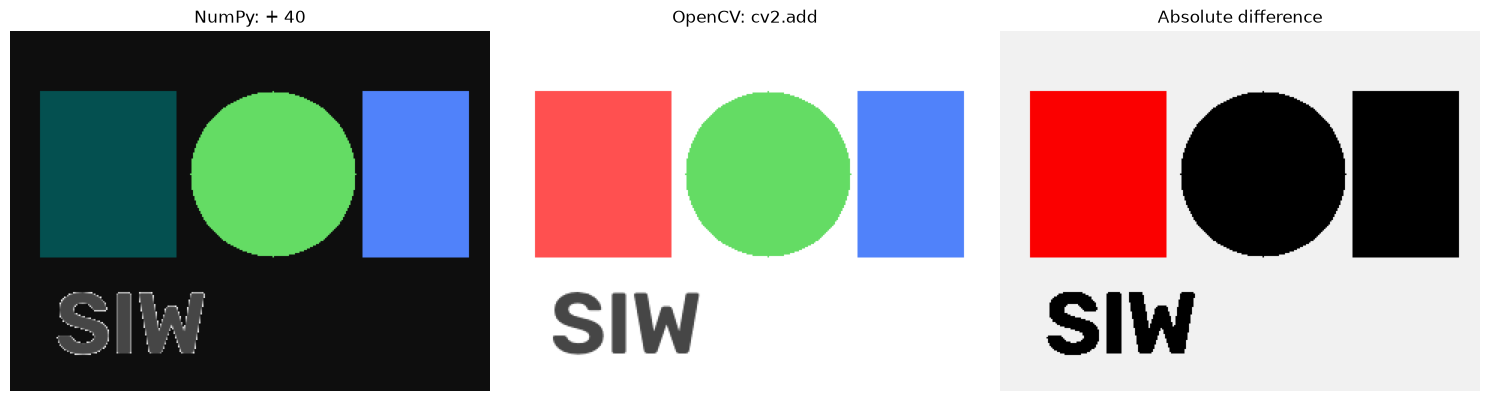

In [7]:
image = wczytaj("scena.png")
bright_numpy = image + 40

increase = np.full_like(image, 40)
bright_cv = cv2.add(image, increase)

diff = cv2.absdiff(bright_numpy, bright_cv)

numpy_rgb = cv2.cvtColor(bright_numpy, cv2.COLOR_BGR2RGB)
cv_rgb = cv2.cvtColor(bright_cv, cv2.COLOR_BGR2RGB)

diff_rgb = cv2.cvtColor(diff, cv2.COLOR_BGR2RGB)

pokaz(
    numpy_rgb,
    cv_rgb,
    diff_rgb,
    tytuly=["NumPy: + 40", "OpenCV: cv2.add", "Absolute difference"],
    rozmiar=5
)

# Wyniki różnią się na jasnym tle i w kanale R czerwonego prostokąta.
# Wartości większe od 215 po dodaniu 40 przekraczają zakres uint8.
# NumPy zawija wynik, a cv2.add ogranicza go do 255.


## 2.3 Kanały barwne

`cv2.split()` rozdziela obraz na kanały, `cv2.merge()` składa je z powrotem. Pojedynczy kanał jest obrazem jednokanałowym, który wyświetlamy w odcieniach szarości.

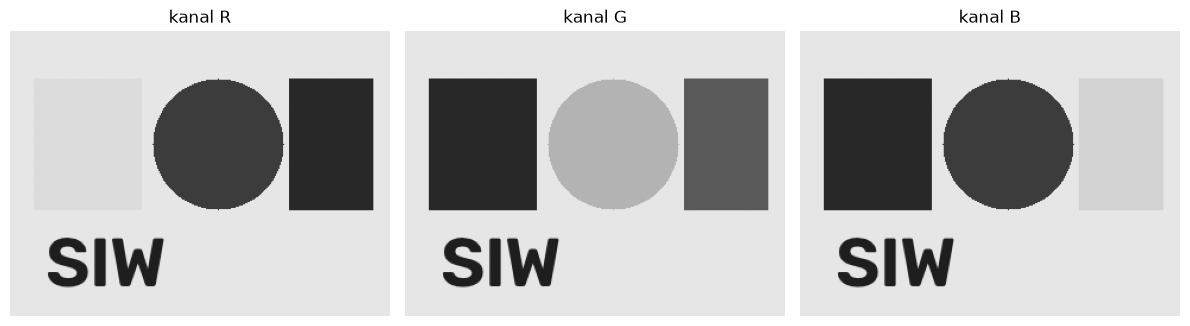

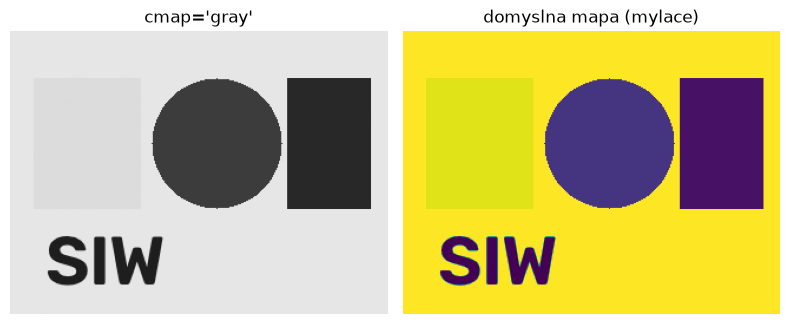

Sredni poziom w obszarze czerwonego prostokata:
  kanal B:   40.0
  kanal G:   40.0
  kanal R:  220.0


In [8]:
bgr = wczytaj("scena.png")
B, G, R = cv2.split(bgr)

pokaz(R, G, B, tytuly=["kanal R", "kanal G", "kanal B"])

# ten sam kanal wyswietlony bez cmap='gray' - matplotlib dokleja wlasna mape kolorow
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(R, cmap="gray", vmin=0, vmax=255); ax[0].set_title("cmap='gray'"); ax[0].axis("off")
ax[1].imshow(R);                                 ax[1].set_title("domyslna mapa (mylace)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

print("Sredni poziom w obszarze czerwonego prostokata:")
for nazwa, kanal in zip("BGR", (B, G, R)):
    print(f"  kanal {nazwa}: {kanal[40:150, 20:110].mean():6.1f}")

Czerwony obiekt jest **najjaśniejszy w kanale R i najciemniejszy w B**. Jest to podstawa najtańszej selekcji barwnej w inspekcji, tzn. zamiast analizować kolor, dobiera się oświetlenie i kanał tak, żeby interesujący nas obiekt miał maksymalny kontrast.

### Do wykonania 2.3

Przy pomocy `cv2.split` i `cv2.merge` należy złożyć obraz z zamienionymi kanałami R i B, a następnie poprawnie go wyświetlić.

Należy takze podać, na którym z kanałów napis „SIW" ma **najmniejszy** kontrast względem tła. Wartość należy uzasadnić liczbowo, a nie "na oko".

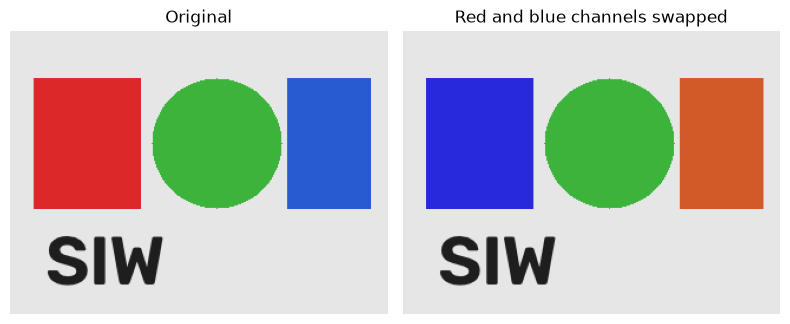

Channel B: text=30.0, background=230.0, contrast=200.0
Channel G: text=30.0, background=230.0, contrast=200.0
Channel R: text=30.0, background=230.0, contrast=200.0


In [9]:
image = wczytaj("scena.png")

blue, green, red = cv2.split(image)

swapped_bgr = cv2.merge((red, green, blue))

original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
swapped_rgb = cv2.cvtColor(swapped_bgr, cv2.COLOR_BGR2RGB)


pokaz(
    original_rgb,
    swapped_rgb,
    tytuly=["Original", "Red and blue channels swapped"]
)



text_mask = np.all(image == (30, 30, 30), axis=2)
background_mask = np.all(image == (230, 230, 230), axis=2)


for name, channel in zip(("B", "G", "R"), (blue, green, red)):
   
    text_mean = channel[text_mask].mean()
    background_mean = channel[background_mask].mean()
    contrast = abs(background_mean - text_mean)


    print(
        f"Channel {name}: text={text_mean:.1f}, "
        f"background={background_mean:.1f}, contrast={contrast:.1f}"
    )

# Kontrast wynosi 200 we wszystkich trzech kanałach.
# Żaden kanał nie ma mniejszego kontrastu, ponieważ napis i tło są szare.

## 2.4 Konwersja do odcieni szarości

`cv2.cvtColor` nie liczy zwykłej średniej kanałów, tylko stosuje wagi luminancji (0,299 R + 0,587 G + 0,114 B), odpowiadające czułości oka człowieka.

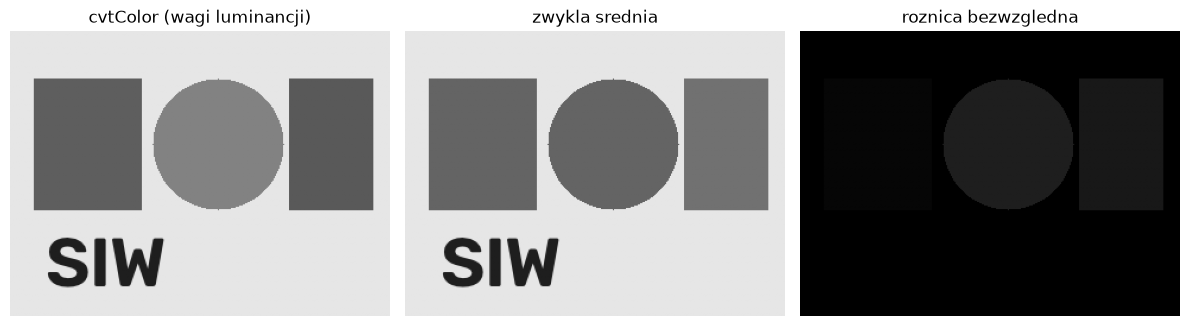

roznica: max = 30  srednia = 6.95


In [10]:
bgr = wczytaj("scena.png")
szary_cv = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
szary_sr = bgr.mean(axis=2).astype(np.uint8)

roznica = cv2.absdiff(szary_cv, szary_sr)
pokaz(szary_cv, szary_sr, roznica,
      tytuly=["cvtColor (wagi luminancji)", "zwykla srednia", "roznica bezwzgledna"])
print("roznica: max =", roznica.max(), " srednia =", round(float(roznica.mean()), 2))

### Do wykonania 2.4

Należy obliczyć obraz w odcieniach szarości ręcznie, według wzoru `0.299·R + 0.587·G + 0.114·B`, wykonując obliczenia na typie `float32`, a następnie zaokrąglić wynik do `uint8`.

Należy sprawdzić, czy wynik jest identyczny z wynikiem `cv2.cvtColor`. Jeżeli nie, to proszę podać maksymalną różnicę i wyjaśnić jej przyczynę.

Equal: True
Max difference: 0


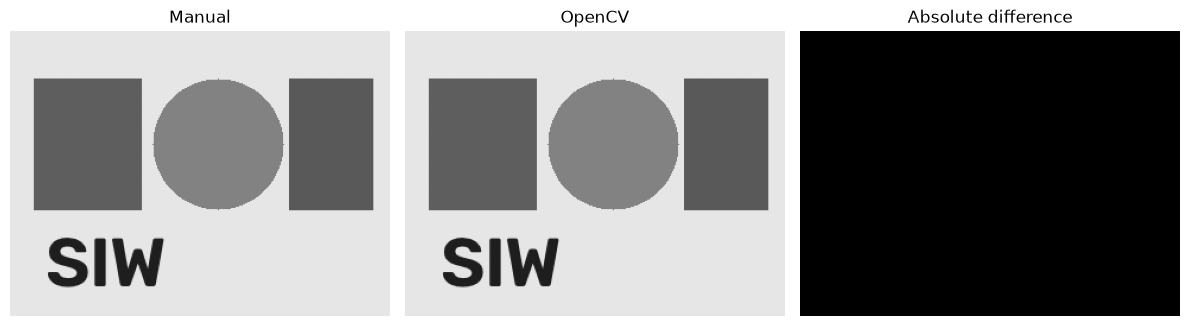

In [11]:
img = wczytaj("scena.png")

b, g, r = cv2.split(img.astype(np.float32))

gray = 0.299 * r + 0.587 * g + 0.114 * b
gray = np.rint(gray).astype(np.uint8)

ref = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

diff = cv2.absdiff(gray, ref)

print("Equal:", np.array_equal(gray, ref))
print("Max difference:", diff.max())

pokaz(
    gray,
    ref,
    diff,
    tytuly=["Manual", "OpenCV", "Absolute difference"]
)

## 2.5 Przekształcenia geometryczne

**Skalowanie.** Metoda interpolacji ma znaczenie i jest inna przy pomniejszaniu niż przy powiększaniu. `INTER_AREA` uśrednia piksel po pikselu i jest właściwa do pomniejszania; `INTER_NEAREST` usuwa co drugi wiersz i kolumnę, co na wzorcu paskowym prowadzi do **aliasingu**.

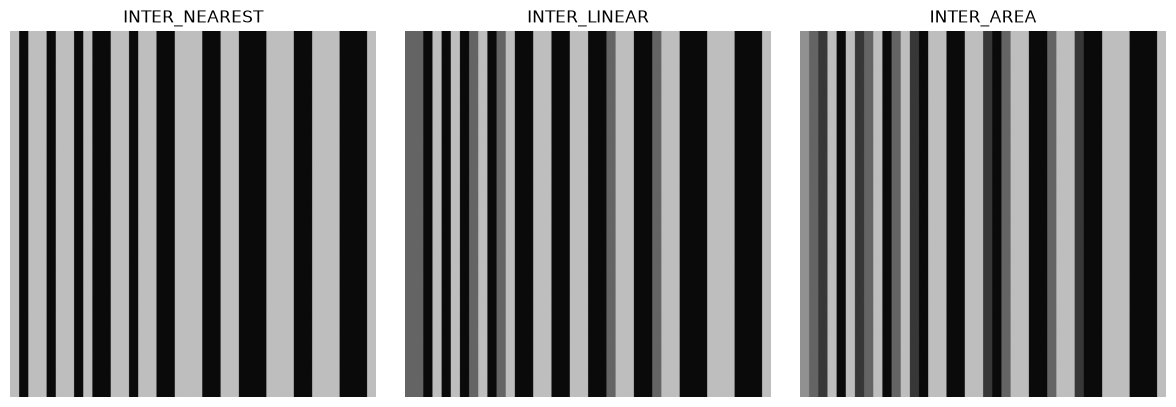

In [12]:
wzorzec = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)
metody = [("INTER_NEAREST", cv2.INTER_NEAREST),
          ("INTER_LINEAR",  cv2.INTER_LINEAR),
          ("INTER_AREA",    cv2.INTER_AREA)]

male = [cv2.resize(wzorzec, None, fx=0.25, fy=0.25, interpolation=m) for _, m in metody]
lupa = [cv2.resize(m[20:60, 0:40], None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST) for m in male]
pokaz(*lupa, tytuly=[n for n, _ in metody])

**Obrót bez obcięcia narożników.** `getRotationMatrix2D` obraca względem zadanego punktu, ale `warpAffine` rysuje wynik na scenie (canvas) o rozmiarze, który sami podamy. Jeżeli podamy rozmiar oryginału, narożniki wyjdą poza kadr. Trzeba przeliczyć nowy rozmiar i dołożyć przesunięcie do macierzy.

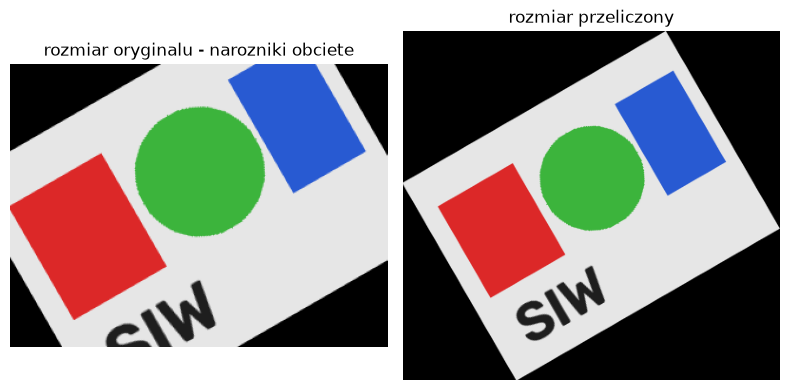

In [13]:
def obroc(obraz, kat):
    h, w = obraz.shape[:2]
    srodek = (w / 2.0, h / 2.0)
    M = cv2.getRotationMatrix2D(srodek, kat, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nW = int(h * sin + w * cos)
    nH = int(h * cos + w * sin)
    M[0, 2] += nW / 2.0 - srodek[0]      # dosuniecie do nowego plotna
    M[1, 2] += nH / 2.0 - srodek[1]
    return cv2.warpAffine(obraz, M, (nW, nH))


scena = cv2.cvtColor(wczytaj("scena.png"), cv2.COLOR_BGR2RGB)
h, w = scena.shape[:2]
M_zle = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), 30, 1.0)
zle = cv2.warpAffine(scena, M_zle, (w, h))

pokaz(zle, obroc(scena, 30), tytuly=["rozmiar oryginalu - narozniki obciete", "rozmiar przeliczony"])

**Przycięcie (ROI).** Zwykłe indeksowanie NumPy, kolejność `[y1:y2, x1:x2]`.

ROI ma ksztalt: (110, 110, 3)


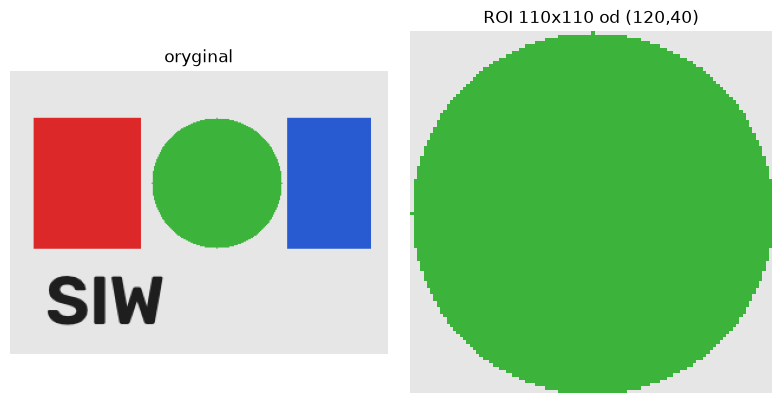

In [14]:
scena = cv2.cvtColor(wczytaj("scena.png"), cv2.COLOR_BGR2RGB)
x, y, szer, wys = 120, 40, 110, 110
roi = scena[y:y + wys, x:x + szer].copy()
print("ROI ma ksztalt:", roi.shape)
pokaz(scena, roi, tytuly=["oryginal", f"ROI {szer}x{wys} od ({x},{y})"])

### Do wykonania 2.5

Wzorzec paskowy należy przeskalować do 40 % rozmiaru metodami `INTER_NEAREST` oraz `INTER_AREA` i dla każdego wyniku podać **liczbę unikalnych poziomów jasności** (`np.unique`).

Należy wyjaśnić, dlaczego liczby te się różnią, mimo że obraz wejściowy zawiera tylko dwa poziomy.

Nearest: [ 10 190] Count: 2
Area: [ 10  46  82 118 190] Count: 5


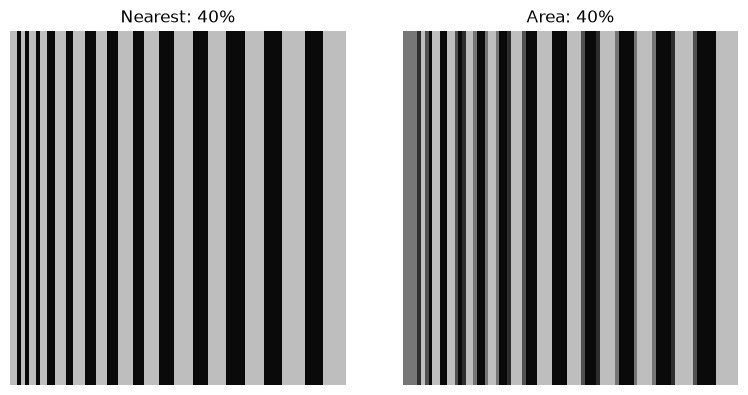

In [15]:
img = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)

near = cv2.resize(img, None, fx=0.4, fy=0.4, interpolation=cv2.INTER_NEAREST)
area = cv2.resize(img, None, fx=0.4, fy=0.4, interpolation=cv2.INTER_AREA)

un = np.unique(near)
ua = np.unique(area)

print("Nearest:", un, "Count:", un.size)
print("Area:", ua, "Count:", ua.size)

pokaz(near, area, tytuly=["Nearest: 40%", "Area: 40%"])

# INTER_NEAREST daje 2 poziomy jasności, a INTER_AREA daje 5.
# NEAREST wybiera istniejące wartości pikseli.
# AREA uśrednia jasne i ciemne fragmenty, tworząc wartości pośrednie.

## 2.6 Progowanie i histogram

Trzy warianty, które trzeba znać:

- **próg stały** - jedna liczba dla całego obrazu, podana ręcznie;
- **Otsu** - próg globalny, ale wyznaczony automatycznie z histogramu (maksymalizuje rozdzielenie dwóch klas);
- **progowanie adaptacyjne** - próg liczony lokalnie, w otoczeniu każdego piksela.

prog wyznaczony przez Otsu: 113.0


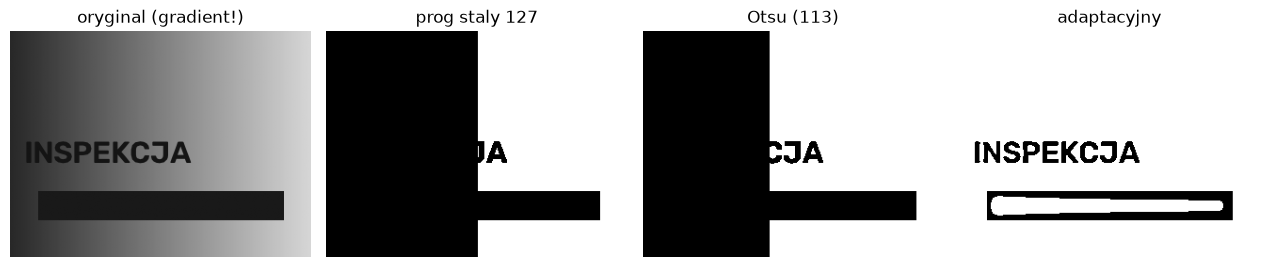

In [16]:
szary = wczytaj("nierowne.png", cv2.IMREAD_GRAYSCALE)

_, b_staly = cv2.threshold(szary, 127, 255, cv2.THRESH_BINARY)
prog_otsu, b_otsu = cv2.threshold(szary, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
b_adapt = cv2.adaptiveThreshold(szary, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY, blockSize=35, C=7)

print("prog wyznaczony przez Otsu:", prog_otsu)
pokaz(szary, b_staly, b_otsu, b_adapt,
      tytuly=["oryginal (gradient!)", "prog staly 127", f"Otsu ({prog_otsu:.0f})", "adaptacyjny"],
      rozmiar=3.2)

Na obrazie z gradientem oświetlenia **żaden próg globalny nie zadziała**, poniwaz ta sama wartość jest tłem po lewej stronie i obiektem po prawej. To nie jest problem algorytmu, tylko problem oświetlenia stanowiska: w prawdziwym systemie inspekcyjnym naprawia się to doświetleniem, a nie progowaniem adaptacyjnym.

**Histogram** pokazuje, dlaczego tak jest.

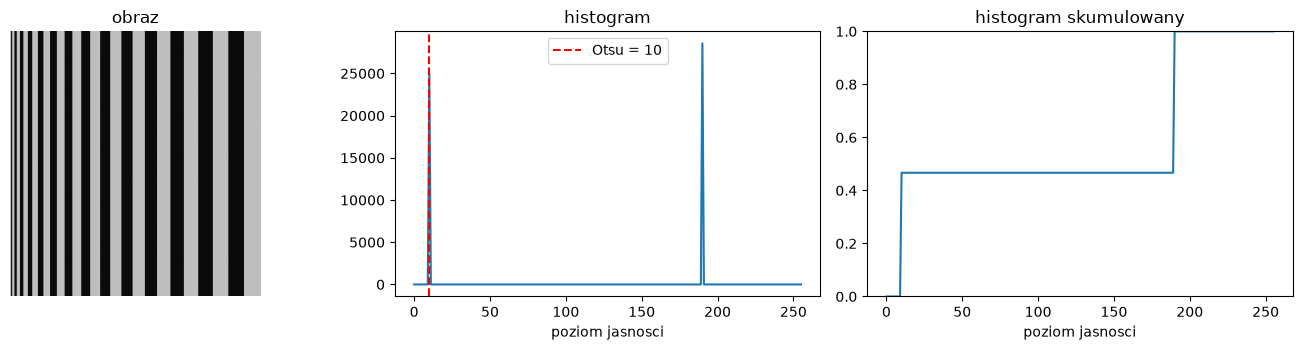

In [17]:
szary = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)
prog_otsu, _ = cv2.threshold(szary, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
hist = cv2.calcHist([szary], [0], None, [256], [0, 256]).ravel()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].imshow(szary, cmap="gray", vmin=0, vmax=255); ax[0].set_title("obraz"); ax[0].axis("off")
ax[1].plot(hist); ax[1].axvline(prog_otsu, color="r", ls="--", label=f"Otsu = {prog_otsu:.0f}")
ax[1].set_title("histogram"); ax[1].set_xlabel("poziom jasnosci"); ax[1].legend()
ax[2].plot(np.cumsum(hist) / hist.sum()); ax[2].set_title("histogram skumulowany")
ax[2].set_xlabel("poziom jasnosci"); ax[2].set_ylim(0, 1)
plt.tight_layout(); plt.show()

### Do wykonania 2.6

Dla obrazu `nierowne.png` należy wyznaczyć próg metodą Otsu **trzykrotnie**: dla całego obrazu, dla jego lewej połowy oraz dla prawej połowy.

Należy zestawić trzy otrzymane wartości i na tej podstawie wyjaśnić, dlaczego pojedynczy próg globalny nie jest w stanie poprawnie zbinaryzować całego obrazu.

Part | Otsu threshold
Whole | 113
Left  | 73
Right | 98


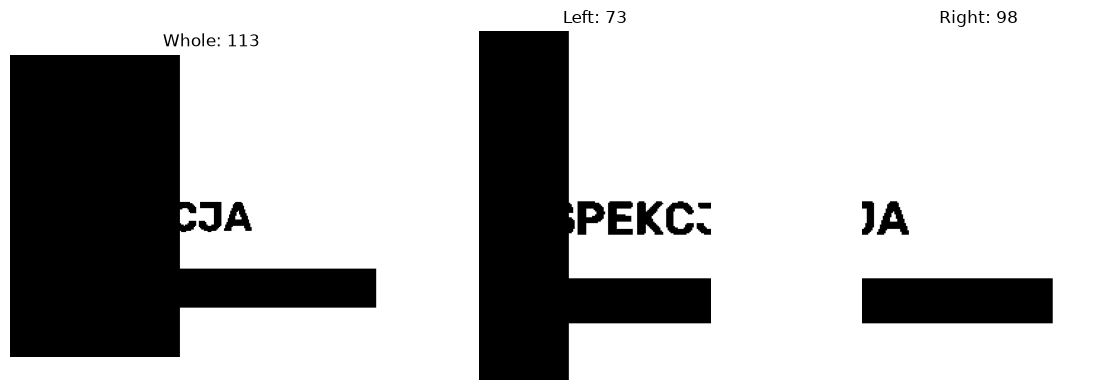

In [18]:
img = wczytaj("nierowne.png", cv2.IMREAD_GRAYSCALE)

mid = img.shape[1] // 2

parts = [
    ("Whole", img),
    ("Left", img[:, :mid]),
    ("Right", img[:, mid:])
]

out, tags = [], []

print("Part | Otsu threshold")

for name, roi in parts:
    t, mask = cv2.threshold(
        roi, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    print(f"{name:5} | {t:.0f}")

    out.append(mask)
    tags.append(f"{name}: {t:.0f}")

pokaz(*out, tytuly=tags)

# Progi Otsu: calosc 113, lewa polowa 73, prawa polowa 98.
# Przy globalnym progu 113 ciemna czesc tla staje sie czarna
# i zlewa sie z napisem, przez co podzial jest niepoprawny.


## 2.7 Zapis obrazu i formaty

`cv2.imwrite()` wybiera format po rozszerzeniu pliku. Trzeci argument to lista parametrów: 

dla JPEG jakość 0–100, 

dla PNG stopień kompresji 0–9 (bezstratny niezależnie od wartości).

wzorzec.png          342 B   roznica max=  0  srednia= 0.00
wzorzec_q90.jpg     9779 B   roznica max=  2  srednia= 0.25
wzorzec_q30.jpg     6726 B   roznica max= 12  srednia= 2.95


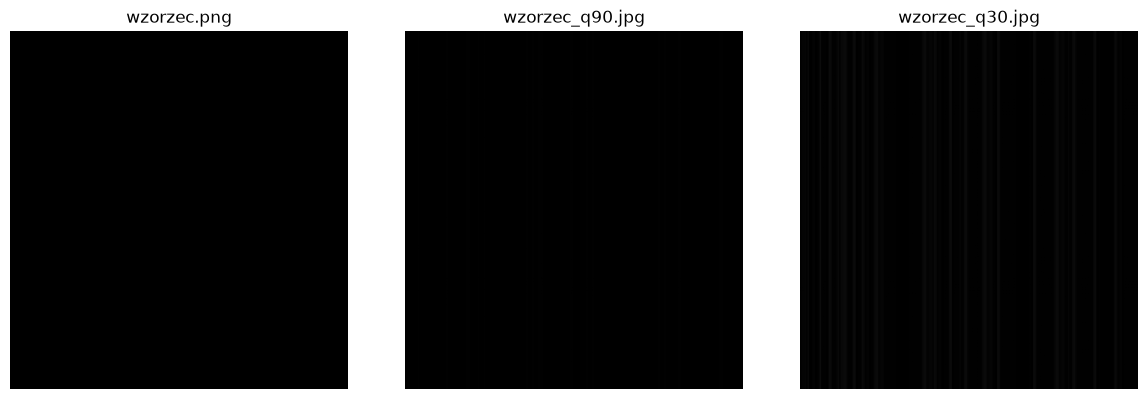

In [19]:
wzorzec = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)

warianty = [("wzorzec.png",     [cv2.IMWRITE_PNG_COMPRESSION, 9]),
            ("wzorzec_q90.jpg", [cv2.IMWRITE_JPEG_QUALITY, 90]),
            ("wzorzec_q30.jpg", [cv2.IMWRITE_JPEG_QUALITY, 30])]

odczytane, podpisy = [], []
for nazwa, parametry in warianty:
    sciezka = WYNIKI / nazwa
    cv2.imwrite(str(sciezka), wzorzec, parametry)
    wrocil = cv2.imread(str(sciezka), cv2.IMREAD_GRAYSCALE)
    roznica = cv2.absdiff(wzorzec, wrocil)
    print(f"{nazwa:16s} {sciezka.stat().st_size:7d} B   "
          f"roznica max={roznica.max():3d}  srednia={roznica.mean():5.2f}")
    odczytane.append(roznica)
    podpisy.append(nazwa)

pokaz(*odczytane, tytuly=podpisy)

Dla PNG różnica jest dokładnie zerowa, a zapis jest bezstratny. Dla JPEG wokół krawędzi pasków pojawiają się **artefakty blokowe i efekt dzwonienia** (*ringing*), tym silniejsze, im niższa jakość.

Należy zwrócić uwagę na rozmiary plików: dla tego obrazu **PNG jest wielokrotnie mniejszy od JPEG**, mimo że jest bezstratny. JPEG został zaprojektowany pod zdjęcia o łagodnych przejściach tonalnych i radzi sobie fatalnie z grafiką o ostrych krawędziach i małej liczbie poziomów. Odwrotna sytuacja wystąpi dla zdjęcia twarzy.

Konsekwencja dla inspekcji wizualnej: artefakt kompresji wygląda w algorytmie dokładnie tak samo jak drobna wada powierzchni. Dlatego obrazy na potrzeby inspekcji archiwizuje się bezstratnie.

### Do wykonania 2.7

Należy powtórzyć porównanie formatów z powyższej komórki dla obrazu `scena.png` (jakość JPEG 90 i 30) i zestawić wyniki z wynikami uzyskanymi dla wzorca paskowego.

Należy wskazać, dla którego z dwóch obrazów format JPEG wypada korzystniej zarówno pod względem rozmiaru pliku, jak i wielkości błędu  oraz wyjaśnić, jaka cecha zawartości obrazu o tym decyduje.

Image | Format | Bytes | Max error | Mean error
wzorzec_paskowy  PNG      342    0   0.000
wzorzec_paskowy  J90     9779    2   0.253
wzorzec_paskowy  J30     6726   12   2.951


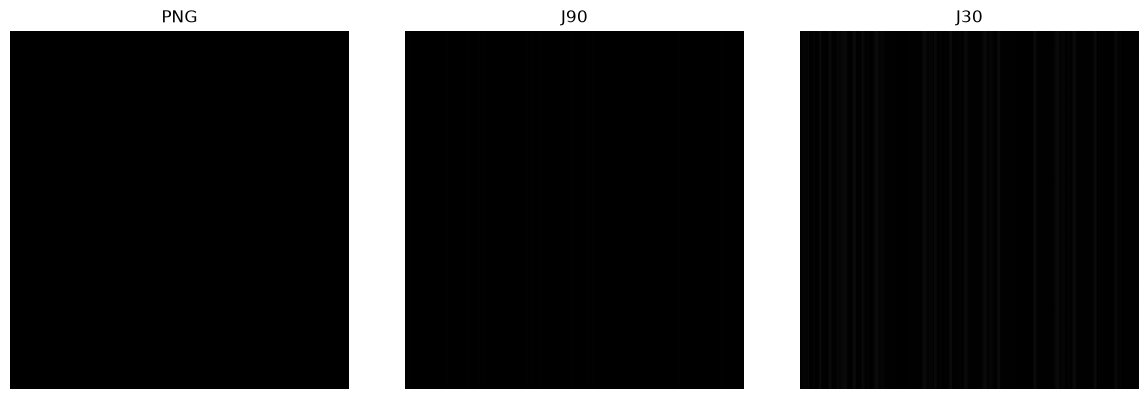

scena            PNG     3424    0   0.000
scena            J90     8398   71   1.348
scena            J30     4166  120   3.546


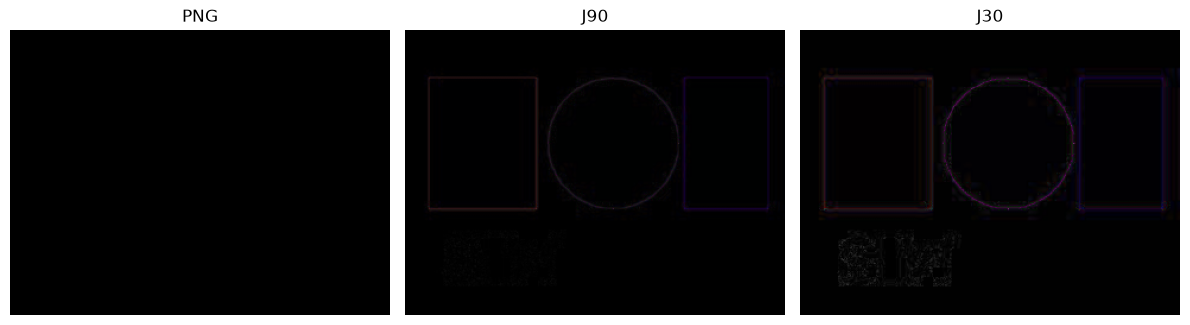

In [20]:
opts = [
    ("PNG", "png", [cv2.IMWRITE_PNG_COMPRESSION, 9]),
    ("J90", "jpg", [cv2.IMWRITE_JPEG_QUALITY, 90]),
    ("J30", "jpg", [cv2.IMWRITE_JPEG_QUALITY, 30])
]

print("Image | Format | Bytes | Max error | Mean error")

for name in ("wzorzec_paskowy", "scena"):
    img = wczytaj(f"{name}.png", cv2.IMREAD_UNCHANGED)

    maps, tags = [], []

    for tag, ext, opt in opts:
        p = WYNIKI / f"{name}_{tag}.{ext}"

        cv2.imwrite(str(p), img, opt)

        rec = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)

        d = cv2.absdiff(img, rec)

        print(
            f"{name:<16} {tag:<4} {p.stat().st_size:>7} "
            f"{d.max():>4} {d.mean():>7.3f}"
        )

        if d.ndim == 3:
            d = cv2.cvtColor(d, cv2.COLOR_BGR2RGB)

        maps.append(d)
        tags.append(tag)

    pokaz(*maps, tytuly=tags)

# JPEG sceny zajmuje mniej miejsca niż JPEG pasków ale daje większy błąd.
# Nie ma więc jednego obrazu korzystniejszego w obu kryteriach
# JPEG zniekształca ostre krawędzie, szczególnie granice kolorów.
# Dla obu obrazów PNG daje mniejszy plik i zerowy błąd.

## 2.8 Sekwencje obrazów

`cv2.VideoCapture` otwiera plik wideo albo kamerę, `cv2.VideoWriter` zapisuje. Obiekty trzeba zwolnić metodą `.release()`.

klatek: 120, fps: 25.0, rozdzielczosc: 320x240, czas: 4.8 s
faktycznie odczytano klatek: 120


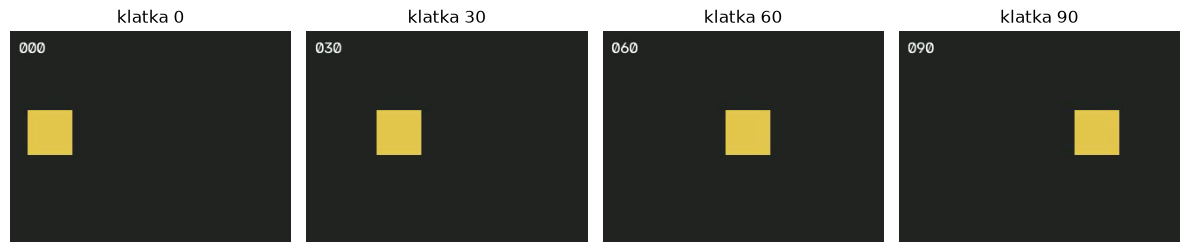

In [21]:
wej = cv2.VideoCapture(str(DANE / "sekwencja.mp4"))

n_klatek = int(wej.get(cv2.CAP_PROP_FRAME_COUNT))
fps      = wej.get(cv2.CAP_PROP_FPS)
szer     = int(wej.get(cv2.CAP_PROP_FRAME_WIDTH))
wys      = int(wej.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"klatek: {n_klatek}, fps: {fps:.1f}, rozdzielczosc: {szer}x{wys}, "
      f"czas: {n_klatek / fps:.1f} s")

wybrane, podpisy = [], []
i = 0
while True:
    ok, klatka = wej.read()
    if not ok:
        break
    if i % 30 == 0:
        wybrane.append(cv2.cvtColor(klatka, cv2.COLOR_BGR2RGB))
        podpisy.append(f"klatka {i}")
    i += 1
wej.release()
print("faktycznie odczytano klatek:", i)

pokaz(*wybrane, tytuly=podpisy, rozmiar=3)

Należy porównać wartość `CAP_PROP_FRAME_COUNT` z liczbą faktycznie odczytanych klatek. Dla wielu kontenerów ta pierwsza wartość jest jedynie szacunkiem z nagłówka pliku i potrafi się nie zgadzać.

Zapis przetworzonej sekwencji: `fourcc` to czteroznakowy kod kodeka, a **rozmiar podany w konstruktorze musi dokładnie odpowiadać rozmiarowi zapisywanych klatek** inaczej powstanie pusty plik, bez żadnego komunikatu o błędzie.

In [22]:
wej = cv2.VideoCapture(str(DANE / "sekwencja.mp4"))
fps  = wej.get(cv2.CAP_PROP_FPS)
szer = int(wej.get(cv2.CAP_PROP_FRAME_WIDTH))
wys  = int(wej.get(cv2.CAP_PROP_FRAME_HEIGHT))

wyj = cv2.VideoWriter(str(WYNIKI / "sekwencja_szara.mp4"),
                      cv2.VideoWriter_fourcc(*"mp4v"), fps, (szer, wys))

zapisane = 0
while True:
    ok, klatka = wej.read()
    if not ok:
        break
    szara = cv2.cvtColor(klatka, cv2.COLOR_BGR2GRAY)
    wyj.write(cv2.cvtColor(szara, cv2.COLOR_GRAY2BGR))   # VideoWriter oczekuje 3 kanalow
    zapisane += 1

wej.release()
wyj.release()

kontrola = cv2.VideoCapture(str(WYNIKI / "sekwencja_szara.mp4"))
print("zapisano klatek :", zapisane)
print("plik ma rozmiar :", (WYNIKI / "sekwencja_szara.mp4").stat().st_size, "B")
print("odczyt zwrotny  :", int(kontrola.get(cv2.CAP_PROP_FRAME_COUNT)), "klatek")
kontrola.release()

zapisano klatek : 120
plik ma rozmiar : 57236 B
odczyt zwrotny  : 120 klatek


### Do wykonania 2.8

Dla sekwencji `sekwencja.mp4` należy wyznaczyć **średnią jasność każdej klatki** i wykreślić ją w funkcji numeru klatki.

Należy podać numer klatki o największej średniej jasności oraz wyjaśnić przebieg otrzymanej krzywej w odniesieniu do zawartości sekwencji.

Brightest frame: 0
Mean brightness: 39.8692


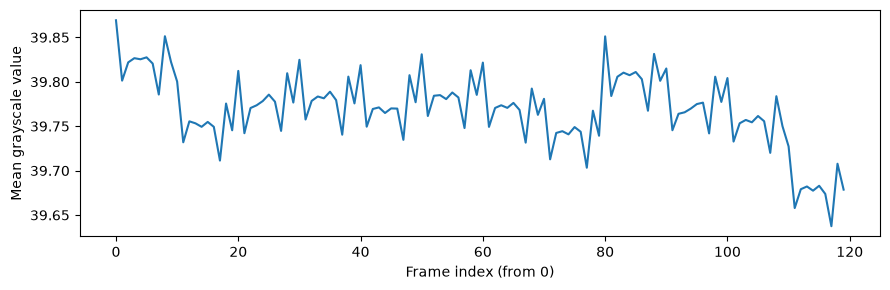

In [23]:
cap = cv2.VideoCapture(str(DANE / "sekwencja.mp4"))

if not cap.isOpened():
    raise OSError("Cannot open video")

vals = []

while True:
    ok, frame = cap.read()

    if not ok:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    vals.append(gray.mean())

cap.release()

if not vals:
    raise ValueError("No frames were read")

vals = np.array(vals)

i = int(vals.argmax())

print("Brightest frame:", i)
print(f"Mean brightness: {vals[i]:.4f}")

plt.figure(figsize=(9, 3))
plt.plot(vals)
plt.xlabel("Frame index (from 0)")
plt.ylabel("Mean grayscale value")
plt.tight_layout()
plt.show()

# Najjaśniejsza jest klatka 0. Wykres średniej jasnosci jest prawie plaski,
# bo przesuwany kwadrat zachowuje rozmiar i kolor na jednolitym tle.
# Male wahania wynikaja ze zmieniajacych sie cyfr i kompresji filmu.

## 2.9 Inspekcja przez porównanie ze wzorcem

Przedmiotem inspekcji jest **tarcza tnąca do szlifierki kątowej**: należy stwierdzić, czy badany egzemplarz nosi ślady wyszczerbienia krawędzi tnącej lub pęknięcia korpusu. Zastosowana zostanie najprostsza znana metoda inspekcji, stanowiąca wciąż podstawę przemysłowych SIW: obraz badany odejmuje się od wzorcowego, a to, co zostaje, uznaje się za wadę.

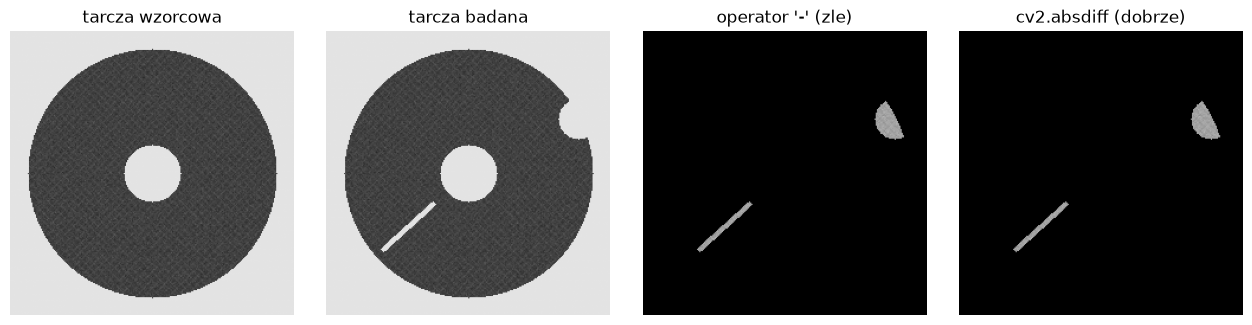

In [24]:
wzorzec = wczytaj("tarcza_wzorzec.png", cv2.IMREAD_GRAYSCALE)
badana  = wczytaj("tarcza_badana.png",  cv2.IMREAD_GRAYSCALE)

zle   = badana - wzorzec                  # uint8: wartosci ujemne zawijaja sie!
dobrze = cv2.absdiff(badana, wzorzec)

pokaz(wzorzec, badana, zle, dobrze,
      tytuly=["tarcza wzorcowa", "tarcza badana", "operator '-' (zle)", "cv2.absdiff (dobrze)"], rozmiar=3.2)

defekt 1: pole= 477 px, bbox=(196,59,25,33)
defekt 2: pole= 255 px, bbox=(46,144,47,43)

lacznie defektow: 2


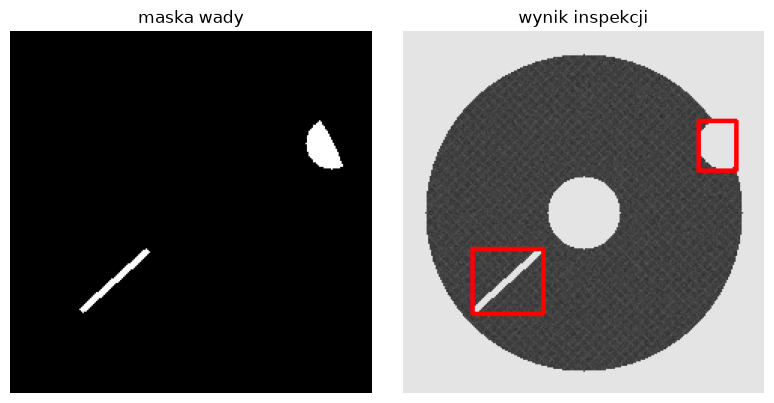

In [25]:
_, maska = cv2.threshold(dobrze, 40, 255, cv2.THRESH_BINARY)
n, etykiety, staty, srodki = cv2.connectedComponentsWithStats(maska, connectivity=8)

wynik = cv2.cvtColor(badana, cv2.COLOR_GRAY2BGR)
znalezione = 0
for i in range(1, n):                       # etykieta 0 to tlo
    x, y, w_, h_, pole = staty[i]
    if pole < 20:                           # odrzucamy drobiazgi
        continue
    znalezione += 1
    cv2.rectangle(wynik, (x, y), (x + w_, y + h_), (0, 0, 255), 2)
    print(f"defekt {znalezione}: pole={pole:4d} px, bbox=({x},{y},{w_},{h_})")

print("\nlacznie defektow:", znalezione)
pokaz(maska, cv2.cvtColor(wynik, cv2.COLOR_BGR2RGB), tytuly=["maska wady", "wynik inspekcji"])

Metoda działa przy dwóch założeniach: 

obraz badany jest **dokładnie spasowany** ze wzorcem (brak przesunięcia, obrotu, zmiany skali) 

oraz ma **tę samą jasność**. Oba założenia łatwo naruszyć, czego dotyczą zadania 5 i 6.

### Do wykonania 2.9

Należy powtórzyć detekcję wad z powyższej komórki dla progu binaryzacji równego 15, 40 oraz 90, pozostawiając `min_pole = 20`.

Dla każdej wartości progu należy podać liczbę wykrytych obszarów oraz ich łączne pole, a wyniki zestawić w tabeli. Należy wskazać, przy którym progu pojawiają się fałszywe alarmy, a przy którym wada zostaje przeoczona.

Threshold | Regions | Total area
       15 |       2 |        732
       40 |       2 |        732
       90 |       2 |        732


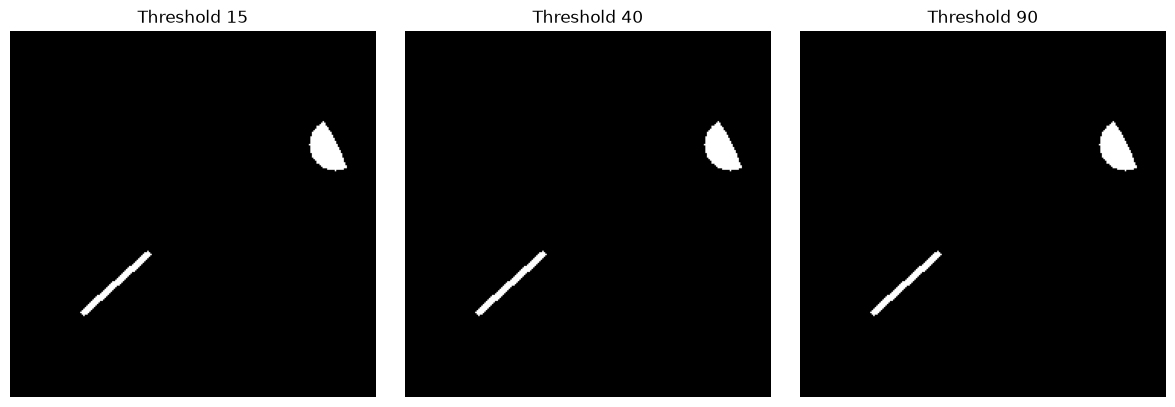

In [26]:
ref = wczytaj("tarcza_wzorzec.png", cv2.IMREAD_GRAYSCALE)
img = wczytaj("tarcza_badana.png", cv2.IMREAD_GRAYSCALE)

d = cv2.absdiff(ref, img)

min_a = 20
masks = []

print("Threshold | Regions | Total area")

for t in (15, 40, 90):
    _, mask = cv2.threshold(d, t, 255, cv2.THRESH_BINARY)

    _, _, st, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )

    a = st[1:, cv2.CC_STAT_AREA]
    a = a[a >= min_a]

    print(f"{t:9d} | {a.size:7d} | {a.sum():10d}")

    masks.append(mask)

pokaz(
    *masks,
    tytuly=["Threshold 15", "Threshold 40", "Threshold 90"]
)

# Dla każdego progu wykryto 2 obszary o łącznym polu 732 pikseli.
# Nie wystąpily fałszywe alarmy ani pominięte wady.
# Różnice w miejscach wad wynoszą 140–184, więc przekraczają każdy badany próg.

***

# 3. Zadania na ocenę

Zadania 1–5 są obowiązkowe, zadania 6–7 dodatkowe. Przy każdym zadaniu należy wypełnić komórkę *Obserwacje i wnioski*; sam kod bez wniosków nie wystarcza do zaliczenia.

| Zadanie | Temat | Punkty |
|---|---|---|
| 1 | Obraz syntetyczny — wzorzec paskowy | 5 |
| 2 | Zapis i formaty — wpływ kompresji | 5 |
| 3 | Szum impulsowy jako funkcja z parametrem | 5 |
| 4 | Progowanie przy nierównomiernym oświetleniu | 5 |
| 5 | Inspekcja przez porównanie z wzorcem | 10 |
| 6 | (dodatkowe) Odporność na przesunięcie i jasność | 5 |
| 7 | (dodatkowe) Detekcja defektu w sekwencji | 5 |

**Razem: sekcja 2 — 10 pkt, sekcja 3 (zadania obowiązkowe) — 30 pkt. Próg zaliczenia ćwiczenia: 20 pkt.**

Funkcje należy implementować **dokładnie z podanymi sygnaturami**, co usprawnia sprawdzanie prac.

## Zadanie 1 (5 pkt)

Należy napisać funkcję `moj_wzorzec(h, w, tlo, pasek)` tworzącą obraz przedstawiony na poniższym przykładzie, a wynik zapisać na dysku pod nazwą `zad1_wzorzec.png`.

**Specyfikacja:** obraz 8-bitowy, jednokanałowy, o rozmiarze 238×225 px (wys.×szer.). Tło o poziomie jasności 10. Na tle pionowe, jasne paski o poziomie 190, rozciągające się na całą wysokość obrazu. Szerokość pasków rośnie od lewej do prawej, zaczynając od 1 px; odstęp między sąsiednimi paskami jest równy szerokości paska po jego lewej stronie. Jest to **wzorzec paskowy** (*bar target*), używany do oceny rozdzielczości układu obrazowania.

Nie należy kopiować funkcji z sekcji 1.1. Po utworzeniu obrazu należy **zweryfikować wynik**: wypisać kształt, typ danych, zbiór występujących poziomów jasności oraz liczbę pasków.

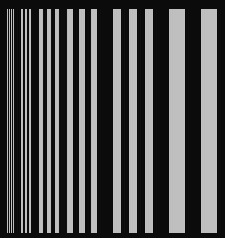

Shape: (238, 225)
Type: uint8
Levels: [ 10 190]
Bars: 15


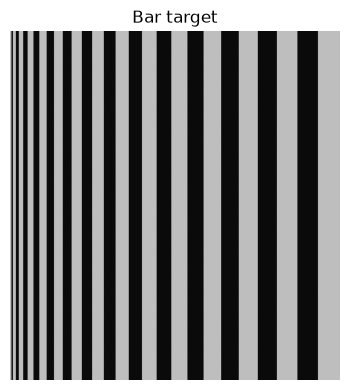

In [27]:
def moj_wzorzec(h=238, w=225, tlo=10, pasek=190):
    img = np.full((h, w), tlo, np.uint8)

    for k in range(1, w + 1):
        x = k * (k - 1)

        if x >= w:
            break

        img[:, x:min(x + k, w)] = pasek

    return img


img = moj_wzorzec()

n, _ = cv2.connectedComponents((img == 190).astype(np.uint8))

print("Shape:", img.shape)
print("Type:", img.dtype)
print("Levels:", np.unique(img))
print("Bars:", n - 1)

cv2.imwrite(str(WYNIKI / "zad1_wzorzec.png"), img)

pokaz(img, tytuly=["Bar target"])


**Obserwacje i wnioski**

*Ile pasków zmieściło się w obrazie i z czego wynika ta liczba? Przy rejestracji wzorca układem o zbyt małej rozdzielczości, które paski zleją się jako pierwsze? W jaki sposób na tej podstawie mozna ocenić rozdzielczość układu obrazowania?*

> 
W obrazie mieści się 15 pasków. Pasek 15 zaczyna się w kolumnie 210 i kończy w 224.
Następny zaczynałby się w kolumnie 240, poza obrazem. Przy małej rozdzielczości najpierw zlewają się najwęższe paski. Najwęższe rozróżnialne paski określają zdolność układu do odtwarzania szczegółów.

## Zadanie 2 (5 pkt)

Wzorzec z zadania 1 należy zapisać w czterech wariantach: `PNG` oraz `JPEG` o jakości 95, 60 i 20.

Dla każdego wariantu:

1. podać rozmiar pliku w bajtach,
2. wczytać plik ponownie i wyznaczyć mapę różnicy bezwzględnej względem oryginału,
3. podać maksimum i wartość średnią tej różnicy,
4. wyświetlić mapy różnicy obok siebie.

Wyniki należy zestawić w czytelnej tabeli (wystarczy `print` z formatowaniem).

Format | Bytes | Max error | Mean error
PNG    |   342 |         0 | 0.0000
J95    | 10529 |         1 | 0.1600
J60    |  7877 |         8 | 1.4889
J20    |  6120 |        16 | 4.6844


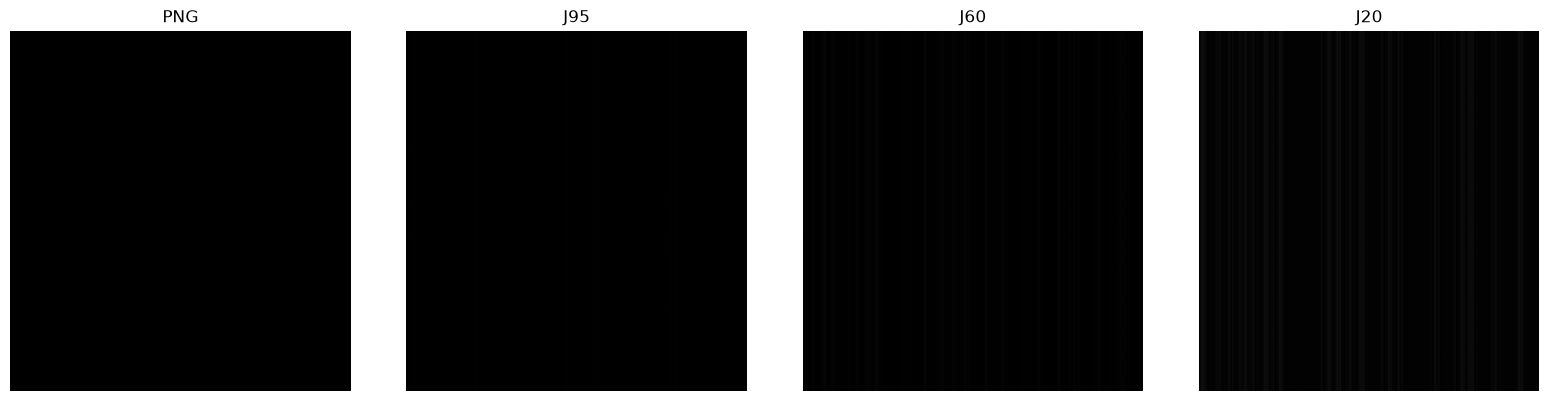

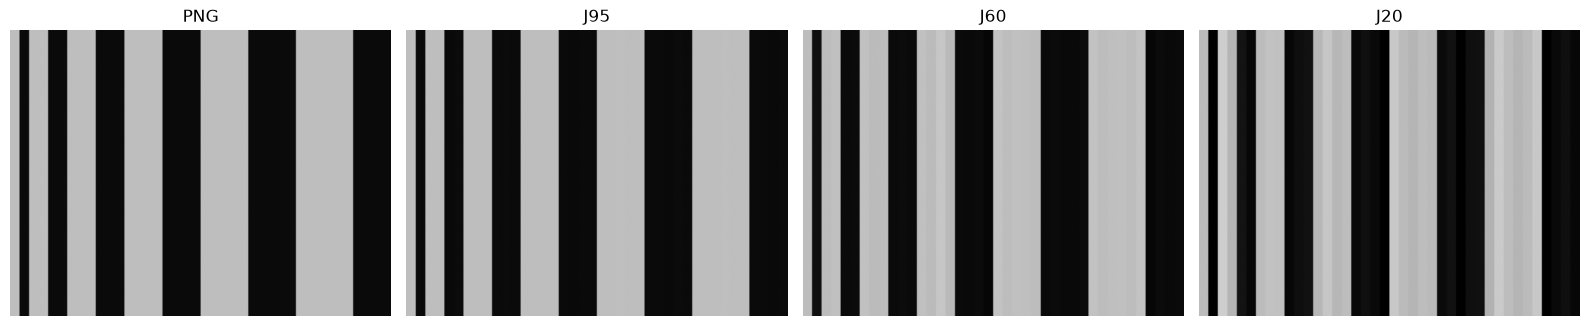

In [28]:
img = moj_wzorzec()

opts = [
    ("PNG", "png", [cv2.IMWRITE_PNG_COMPRESSION, 9]),
    ("J95", "jpg", [cv2.IMWRITE_JPEG_QUALITY, 95]),
    ("J60", "jpg", [cv2.IMWRITE_JPEG_QUALITY, 60]),
    ("J20", "jpg", [cv2.IMWRITE_JPEG_QUALITY, 20])
]

maps, zooms, tags = [], [], []

print("Format | Bytes | Max error | Mean error")

for tag, ext, opt in opts:
    p = WYNIKI / f"zad2_{tag}.{ext}"

    cv2.imwrite(str(p), img, opt)

    rec = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)

    d = cv2.absdiff(img, rec)

    print(
        f"{tag:6} | {p.stat().st_size:5d} | "
        f"{d.max():9d} | {d.mean():.4f}"
    )

    zoom = cv2.resize(
        rec[:30, :40],
        None,
        fx=5,
        fy=5,
        interpolation=cv2.INTER_NEAREST
    )

    maps.append(d)
    zooms.append(zoom)
    tags.append(tag)

pokaz(*maps, tytuly=tags)
pokaz(*zooms, tytuly=tags)


**Obserwacje i wnioski**

*Przy której wartości parametru jakości JPEG najwęższe paski ulegają zniekształceniu na tyle, że przestają być rozróżnialne? Jak wygląda artefakt w otoczeniu krawędzi i jaka jest jego przyczyna? Dlaczego do archiwizacji obrazów na potrzeby inspekcji wizualnej nie stosuje się formatu JPEG?  Należy podać konkretny scenariusz, w którym artefakt zostałby uznany za wadę.*

> 
PNG zachowuje wszystkie wartosci pikseli. Najwiekszy blad daje JPEG 20, ale najwezsze paski nadal sa rozróznialne. Przy krawędziach pojawiają się jasniejsze i ciemniejsze pasma, czyli ringing.
Powstaja przez stratne odrzucanie informacji podczas kompresji JPEG.
Artefakt moze zostać uznany za wade: przy progu róznicy 10 bledy JPEG 20, dochodzace do 16, moga uruchomic falszywy alarm.

## Zadanie 3 (5 pkt)

Należy napisać funkcję `szum_impulsowy(obraz, p, ziarno=0)` zwracającą **kopię** obrazu, w której zaburzeniu uległ udział `p` pikseli: piksel ciemny zamieniany jest na biały (255), piksel jasny na czarny (0). Progiem rozdzielenia „ciemny / jasny" jest wartość 128.

Wymagania:

- funkcja nie modyfikuje obrazu wejściowego,
- wynik jest powtarzalny dla tej samej wartości `ziarno` (należy zastosować `np.random.default_rng(ziarno)`),
- dla `p` = 0,01, 0,05 i 0,20 należy wyświetlić wyniki obok siebie,
- dla każdej wartości `p` należy policzyć, **ile pikseli uległo faktycznej zmianie**, i porównać z wartością oczekiwaną `p * liczba_pikseli`.

p | Changed | Expected
0.01 |     536 | 535.5
0.05 |    2659 | 2677.5
0.20 |   10714 | 10710.0
Input unchanged: True
Repeatable: True


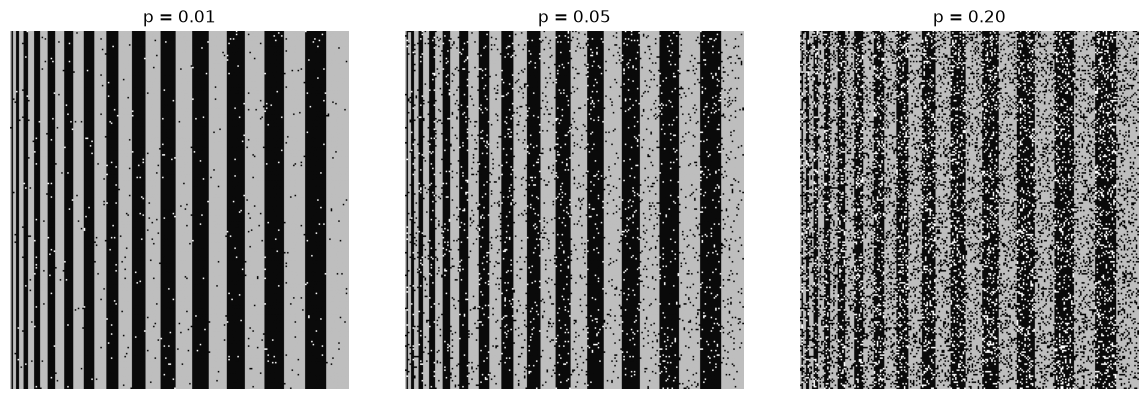

In [29]:
def szum_impulsowy(obraz, p, ziarno=0):
    if not 0 <= p <= 1:
        raise ValueError("p must be between 0 and 1")

    if obraz.ndim != 2:
        raise ValueError("Expected a grayscale image")

    rng = np.random.default_rng(ziarno)

    out = obraz.copy()

    mask = rng.random(obraz.shape) < p

    out[mask] = np.where(obraz[mask] < 128, 255, 0)

    return out


img = moj_wzorzec()
src = img.copy()

imgs, tags = [], []

print("p | Changed | Expected")

for p in (0.01, 0.05, 0.20):
    out = szum_impulsowy(img, p)

    n = np.count_nonzero(out != img)

    print(f"{p:.2f} | {n:7d} | {p * img.size:.1f}")

    imgs.append(out)
    tags.append(f"p = {p:.2f}")

print("Input unchanged:", np.array_equal(img, src))

print(
    "Repeatable:",
    np.array_equal(
        szum_impulsowy(img, 0.05),
        szum_impulsowy(img, 0.05)
    )
)

pokaz(*imgs, tytuly=tags)

**Obserwacje i wnioski**

*Czy liczba zmienionych pikseli zgadza się z wartością oczekiwaną? Jeżeli nie, to skąd się wzięła rozbieżność w przyjętej implementacji? Jak nazywa się ten rodzaj zaburzenia? Przy której gęstości szumu najwęższe paski wzorca przestają być rozróżnialne?*

> 
Jest to szum impulsowy typu sol i pieprz. Liczba zmian jest bliska p * liczba_pikseli, ale nie musi być identyczna. Kazdy piksel jest losowany niezaleznie, wiec liczba zmian podlega wahaniom. Przy p=0.20 paski sa najbardziej zaklócone, ale nadal mozna je dostrzec. Oryginał pozostaje bez zmian, a to samo ziarno daje ten sam wynik.

## Zadanie 4 (5 pkt)

Dla obrazu `nierowne.png` (lub własnego zdjęcia kartki oświetlonej jednostronnie) należy wykonać binaryzację trzema metodami: próg stały, metoda Otsu oraz progowanie adaptacyjne.

1. Wyświetlić wyniki obok siebie i wypisać próg wyznaczony metodą Otsu.
2. Dobrać parametry `blockSize` oraz `C` progowania adaptacyjnego tak, aby napis był czytelny na całej szerokości obrazu; przedstawić wynik dla co najmniej trzech różnych wartości `blockSize`.
3. Wykreślić histogram obrazu z zaznaczonym progiem Otsu.

Otsu threshold: 113.0


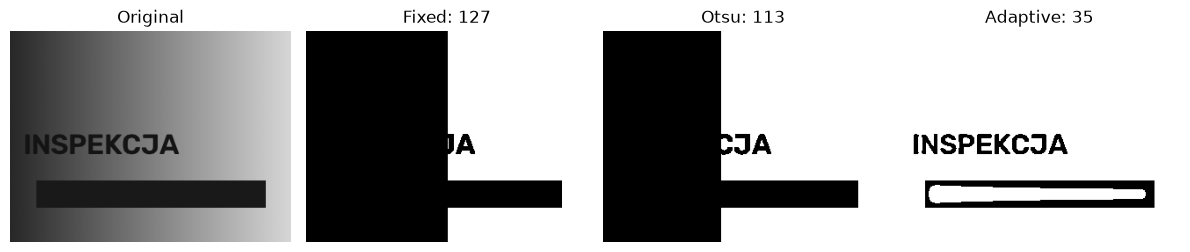

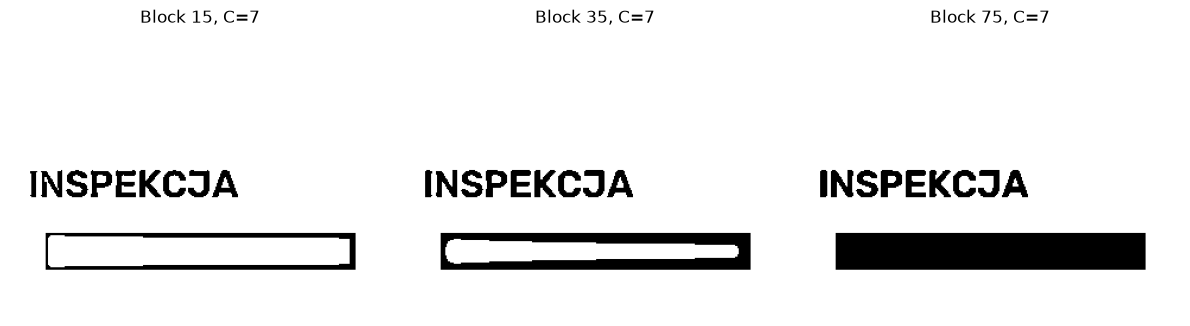

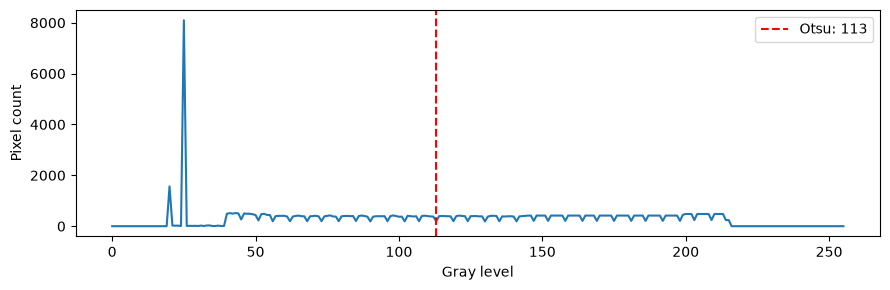

In [30]:
img = wczytaj("nierowne.png", cv2.IMREAD_GRAYSCALE)

_, fixed = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

t, otsu = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

bs = (15, 35, 75)
c = 7

imgs, tags = [], []

for b in bs:
    out = cv2.adaptiveThreshold(
        img,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        b,
        c
    )

    imgs.append(out)
    tags.append(f"Block {b}, C={c}")

print("Otsu threshold:", t)

pokaz(
    img,
    fixed,
    otsu,
    imgs[1],
    tytuly=["Original", "Fixed: 127", f"Otsu: {t:.0f}", "Adaptive: 35"],
    rozmiar=3
)

pokaz(*imgs, tytuly=tags)

hist = cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()

plt.figure(figsize=(9, 3))
plt.plot(hist)
plt.axvline(t, color="red", linestyle="--", label=f"Otsu: {t:.0f}")
plt.xlabel("Gray level")
plt.ylabel("Pixel count")
plt.legend()
plt.tight_layout()
plt.show()

**Obserwacje i wnioski**

*W którym obszarze obrazu próg globalny zawiódł i jaka jest tego przyczyna? Jak zmiana parametru blockSize wpływa na wynik - co następuje przy wartości zbyt małej, a co przy zbyt dużej? Który z omawianych problemów należałoby rozwiązać zmianą oświetlenia stanowiska, a nie zmianą w kodzie?*

> 
Otsu wybrał próg 113. Ciemna część tła po lewej zlewa się z obiektami. Progowanie adaptacyjne zachowuje czytelny napis przy C=7. Mały blok 15 powoduje zanikanie wnętrza dużego prostokąta. Blok 75 zachowuje tutaj cały prostokąt i czytelny napis. Zbyt duże otoczenie może ponownie objąć duże zmiany oświetlenia. W stanowisku należy poprawić równomierność oświetlenia. W tym generatorze odpowiednio niski próg globalny także może oddzielić jednolite wnętrza obiektów od tła.

## Zadanie 5 (10 pkt)

Należy napisać funkcję `znajdz_defekty(wzorzec, badana, prog=40, min_pole=20)` zwracającą listę krotek `(x, y, w, h, pole)` opisujących wykryte obszary różniące się od wzorca.

Następnie należy zastosować ją do pary `tarcza_wzorzec.png` / `tarcza_badana.png`, przedstawiającej **tarczę tnącą do szlifierki kątowej** - egzemplarz wzorcowy oraz egzemplarz podlegający ocenie (można również wykorzystać zdjęcia tarcz udostępnione na e-portalu). Należy:

1. wyświetlić mapę różnicy oraz maskę defektu,
2. nanieść wykryte obszary na obraz badany w postaci prostokątów okalających,
3. wypisać liczbę wykrytych wad, pole każdej z nich oraz określić ich rodzaj (wyszczerbienie krawędzi tnącej, pęknięcie korpusu),
4. zbadać zmianę wyniku dla progu 20, 40 i 80 — liczbę wykrytych obszarów zestawić w tabeli.

Defect 1: area=477, box=(196, 59, 25, 33)
Defect 2: area=255, box=(46, 144, 47, 43)
Total defects: 2
Upper-right area: edge chip
Lower-left area: body crack


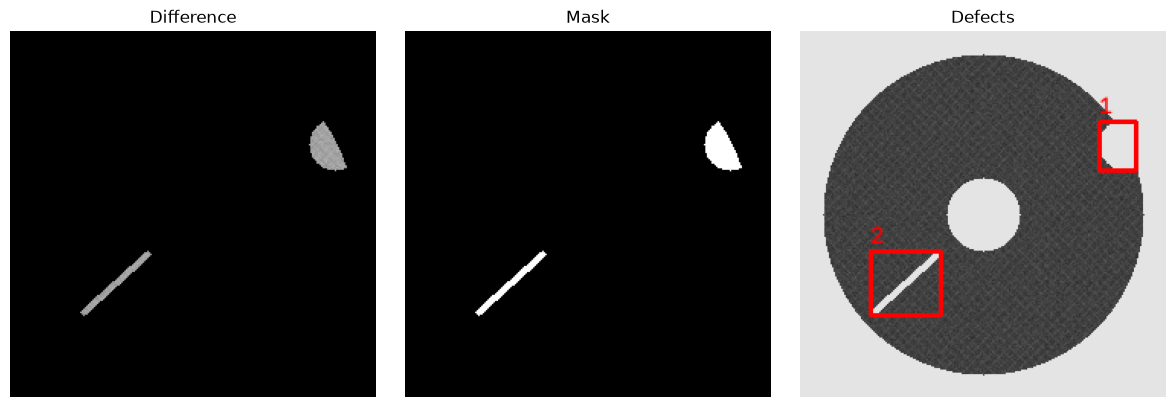

Threshold | Regions
       20 |       2
       40 |       2
       80 |       2


In [31]:
def znajdz_defekty(wzorzec, badana, prog=40, min_pole=20):
    d = cv2.absdiff(wzorzec, badana)

    _, mask = cv2.threshold(d, prog, 255, cv2.THRESH_BINARY)

    n, _, st, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )

    out = []

    for i in range(1, n):
        x, y, w, h, a = map(int, st[i])

        if a >= min_pole:
            out.append((x, y, w, h, a))

    return out


ref = wczytaj("tarcza_wzorzec.png", cv2.IMREAD_GRAYSCALE)
img = wczytaj("tarcza_badana.png", cv2.IMREAD_GRAYSCALE)

d = cv2.absdiff(ref, img)
_, mask = cv2.threshold(d, 40, 255, cv2.THRESH_BINARY)

hits = znajdz_defekty(ref, img)

out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

for i, (x, y, w, h, a) in enumerate(hits, 1):
    cv2.rectangle(
        out,
        (x, y),
        (x + w - 1, y + h - 1),
        (0, 0, 255),
        2
    )

    cv2.putText(
        out,
        str(i),
        (x, max(15, y - 5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 0, 255),
        1
    )

    print(f"Defect {i}: area={a}, box=({x}, {y}, {w}, {h})")

print("Total defects:", len(hits))
print("Upper-right area: edge chip")
print("Lower-left area: body crack")

pokaz(
    d,
    mask,
    cv2.cvtColor(out, cv2.COLOR_BGR2RGB),
    tytuly=["Difference", "Mask", "Defects"]
)

print("Threshold | Regions")

for t in (20, 40, 80):
    print(f"{t:9d} | {len(znajdz_defekty(ref, img, prog=t)):7d}")


**Obserwacje i wnioski**

*Czym różni się wynik operatora '-' od funkcji cv2.absdiff dla typu uint8 i dlaczego ta różnica jest istotna w inspekcji wizualnej? W jaki sposób dobrano próg i czy istnieje wartość, przy której nie występują ani fałszywe alarmy, ani przeoczenia? W jakim celu odrzuca się obszary mniejsze niż min_pole i jakie ryzyko wiąże się ze zwiększaniem tego parametru?*

> 
Wykryto wyszczerbienie po prawej u góry: 477 pikseli oraz pęknięcie po lewej na dole: 255 pikseli Progi 20, 40 i 80 dają po 2 wykrycia, bez fałszywych alarmów. min_pole usuwa drobne obszary, ale zwiększenie go może ukryć małą wadę. Operator "-" na uint8 zawija wyniki ujemne, a absdiff liczy moduł różnicy. W tej parze badana-wzorzec daje taki sam wynik jak absdiff, ponieważ uszkodzenia odsłaniają jaśniejsze tło. Próg 40 zachowuje obie wady, ponieważ różnice w ich obszarach wynoszą 140–184, a poza wadami różnica wynosi 0.

## Zadanie 6 - dodatkowe (5 pkt)

Należy zbadać, w jakim stopniu metoda z zadania 5 jest odporna na naruszenie przyjętych w niej założeń.

1. **Przesunięcie:** przesunąć obraz badany o 1, 2 i 5 px w poziomie (`np.roll` lub `warpAffine`) i dla każdego przesunięcia podać liczbę wykrytych obszarów oraz ich łączne pole.
2. **Jasność:** pomnożyć obraz badany przez 1,15 (z nasyceniem, `cv2.convertScaleAbs`) i powtórzyć detekcję.
3. Zaproponować i zaimplementować **korekcję jasności** przed odejmowaniem (np. dopasowanie wartości średniej i odchylenia standardowego obrazu badanego do wzorca). Porównać liczbę fałszywych alarmów przed korekcją i po niej.

Shift | Regions | Total area
    0 |       2 |        732
    1 |       5 |       1055
    2 |       5 |       1570
    5 |       5 |       2970
Version | Regions | Total area | False alarms
Bright  |       2 |        732 |            0
Fixed   |       2 |        732 |            0


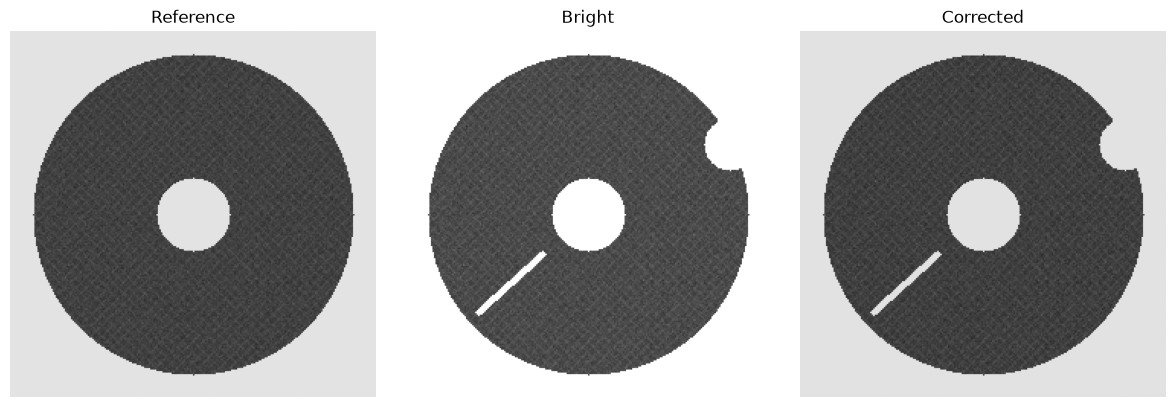

In [32]:
ref = wczytaj("tarcza_wzorzec.png", cv2.IMREAD_GRAYSCALE)
img = wczytaj("tarcza_badana.png", cv2.IMREAD_GRAYSCALE)

print("Shift | Regions | Total area")

for dx in (0, 1, 2, 5):
    shifted = np.roll(img, dx, axis=1)

    hits = znajdz_defekty(ref, shifted)

    print(
        f"{dx:5d} | {len(hits):7d} | "
        f"{sum(v[4] for v in hits):10d}"
    )

bright = cv2.convertScaleAbs(img, alpha=1.15)

f = bright.astype(np.float32)
f = (f - f.mean()) * (ref.std() / f.std()) + ref.mean()

fixed = np.clip(np.rint(f), 0, 255).astype(np.uint8)

truth = cv2.absdiff(ref, img) > 40

print("Version | Regions | Total area | False alarms")

for name, src in (("Bright", bright), ("Fixed", fixed)):
    hits = znajdz_defekty(ref, src)

    _, mask = cv2.threshold(
        cv2.absdiff(ref, src), 40, 255, cv2.THRESH_BINARY
    )

    n, lab, st, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )

    fp = 0

    for k in range(1, n):
        if (
            st[k, cv2.CC_STAT_AREA] >= 20
            and not np.any(truth[lab == k])
        ):
            fp += 1

    print(
        f"{name:7} | {len(hits):7d} | "
        f"{sum(v[4] for v in hits):10d} | {fp:12d}"
    )

pokaz(ref, bright, fixed, tytuly=["Reference", "Bright", "Corrected"])

**Obserwacje i wnioski**

*Przy jakim przesunięciu metoda przestaje być użyteczna? O ile zmniejszyła się liczba fałszywych alarmów po korekcji jasności? Który z dwóch rozpatrywanych problemów (przesunięcie czy jasność) taniej jest rozwiązać w torze akwizycji niż w kodzie, i w jaki sposób?*

> 
Bez przesuniecia: 2 obszary, pole 732. Przesuniecia 1, 2 i 5 px daja po 5 obszarow, o lącznych polach 1055, 1570 i 2970 pikseli. Nawet przesunięcie 1 px powoduje dodatkowe wykrycia na krawędziach. Rozjaśnienie o 15% przy progu 40 nie powoduje tu fałszywych alarmów. Przed korekcja i po niej liczba falszywych alarmow wynosi 0. W pierwszej kolejnosci warto ustabilizowac pozycje elementu uchwytem. Jasnosc nalezy stabilizować stalym oświetleniem i ekspozycja.

## Zadanie 7 — dodatkowe (5 pkt)

Dla sekwencji `sekwencja.mp4` należy wyznaczyć klatkę, w której obiekt przekracza zadaną pozycję poziomą (np. x = 200 px).

1. Przejść po kolejnych klatkach, wyznaczając w każdej położenie środka jasnego obiektu (progowanie oraz `cv2.moments` lub `connectedComponentsWithStats`).
2. Wykreślić położenie x w funkcji numeru klatki.
3. Podać numer klatki oraz czas (w sekundach), w którym nastąpiło przekroczenie.
4. Zapisać sekwencję wyjściową z naniesionym prostokątem okalającym obiekt oraz numerem klatki.

Crossing frame: 78
Crossing time: 3.12 s
Output: wyniki/zad7_track.mp4


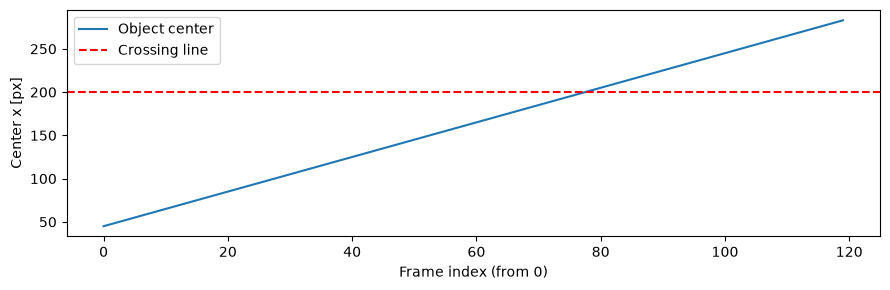

In [33]:
cap = cv2.VideoCapture(str(DANE / "sekwencja.mp4"))

if not cap.isOpened():
    raise OSError("Cannot open video")

fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

p = WYNIKI / "zad7_track.mp4"

writer = cv2.VideoWriter(
    str(p),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (w, h)
)

if not writer.isOpened():
    cap.release()
    raise OSError("Cannot create output video")

xs = []
cross = None
limit = 200
i = 0

try:
    while True:
        ok, frame = cap.read()

        if not ok:
            break

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        _, mask = cv2.threshold(
            gray, 120, 255, cv2.THRESH_BINARY
        )

        n, _, st, centers = cv2.connectedComponentsWithStats(
            mask, connectivity=8
        )

        cx = np.nan

        if n > 1:
            k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))

            x, y, bw, bh, a = map(int, st[k])

            cx = float(centers[k, 0])

            cv2.rectangle(
                frame,
                (x, y),
                (x + bw - 1, y + bh - 1),
                (0, 0, 255),
                2
            )

            if cross is None and cx > limit:
                cross = i

        cv2.putText(
            frame,
            f"Frame {i}",
            (10, 50),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 0, 255),
            2
        )

        writer.write(frame)

        xs.append(cx)
        i += 1

finally:
    cap.release()
    writer.release()

if cross is None:
    print("The object did not cross the line")
else:
    print("Crossing frame:", cross)
    print(f"Crossing time: {cross / fps:.2f} s")

print("Output:", p)

plt.figure(figsize=(9, 3))
plt.plot(xs, label="Object center")
plt.axhline(
    limit,
    color="red",
    linestyle="--",
    label="Crossing line"
)
plt.xlabel("Frame index (from 0)")
plt.ylabel("Center x [px]")
plt.legend()
plt.tight_layout()
plt.show()


**Obserwacje i wnioski**

*Czy trajektoria jest idealnie liniowa? Jeżeli nie, jakie jest źródło odchyleń? Jaka jest niepewność wyznaczenia pozycji w pikselach i co ją ogranicza? Jak zachowałaby się ta metoda w przypadku pojawienia się w kadrze drugiego jasnego obiektu?*

> 
Środek obiektu przekracza x=200 w klatce 78, czyli po 3.12 s. W tej sekwencji trajektoria jest liniowa: środek przesuwa się o 2 px na klatkę. Wykryte pozycje zgadzają się z pozycjami wynikającymi z generatora. Dokładność w innych obrazach ograniczają piksele, kompresja i wybór progu. Ułamkowa współrzędna środka nie gwarantuje dokładności mniejszej niż piksel. Przy drugim jasnym obiekcie metoda wybierze większy obszar, więc może przełączyć się na inny obiekt.
Orientacyjnie przyjmuję niepewność położenia rzędu 1 px, zakładając możliwość przesunięcia granicy maski o jeden piksel. 

***

> 